# Práctica final PySpark: Insurance

A partir del dataset de costes médicos de un seguro de salud, se realiza un Análisis Exploratorio de Datos (EDA) con la API de pandas de PySpark y se entrena con `pyspark.ml` un modelo de **Regresión Lineal** (y después un **Random Forest**) que predice los costes médicos (`charges`).

## Índice

1. Instalación y librerías
2. Carga y descripción de los datos
3. Análisis univariante
4. Análisis bivariante
5. Regresión lineal
6. Random Forest
7. Conclusiones

## 1. Instalación y librerías

In [1]:
import os
import sys
import warnings

#Probado con PySpark 4.0.4 (la 4.0.0 falla en Windows) y Java 17: pip install pyspark==4.0.4

#Si lo abres en Google Colab, quita el # de estas tres líneas para instalar PySpark y Java:
#!pip install pyspark==4.0.4
#!apt-get install openjdk-17-jdk-headless -qq > /dev/null
#os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

#Spark usa este mismo Python para sus procesos
os.environ["PYSPARK_PYTHON"] = sys.executable
#Si SPARK_HOME apunta a una carpeta que no existe, Spark no arranca
if not os.path.exists(os.environ.get("SPARK_HOME", "")):
    os.environ.pop("SPARK_HOME", None)

#Ocultamos los avisos de PySpark para que se lean bien las salidas
warnings.filterwarnings('ignore')

#Análisis exploratorio y gráficos
import pyspark.pandas as ps
import matplotlib.pyplot as plt
import seaborn as sns

#Machine learning
from pyspark.sql import SparkSession
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#Sesión de Spark
spark = (SparkSession.builder
         .config("spark.sql.ansi.enabled", "false")
         .config("spark.sql.shuffle.partitions", "4")
         .getOrCreate())

## 2. Carga y descripción de los datos

In [2]:
#Carga del dataset
df = ps.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
#Tamaño (filas, columnas) y tipos de datos
print(df.shape)
df.info()

(1338, 7)


<class 'pyspark.pandas.frame.DataFrame'>
Index: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int32  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int32  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int32(2), object(3)

Vemos que el dataset está completo y no hay valores nulos.

In [4]:
#Comprobamos si hay registros duplicados
df.duplicated().sum()

1

In [5]:
#Los eliminamos para que no cuenten dos veces
df = df.drop_duplicates()
df.shape

(1337, 7)

In [6]:
#Estadísticas de las variables numéricas
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


- **Edad:** la mitad de los clientes tiene entre 27 y 51 años, y la media es de 39.
- **BMI:** el ideal está entre 18,5 y 24,9, pero la media y la mediana rondan el 30 y la mitad de los clientes está entre 26 y 34. Es un rango elevado.
- **Cargos:** la media es de 13.279, pero la mediana es de 9.386 y la mitad paga entre 4.746 y 16.657. Es decir, la mayoría paga poco y unos pocos pagan muchísimo (la desviación es casi igual que la media).

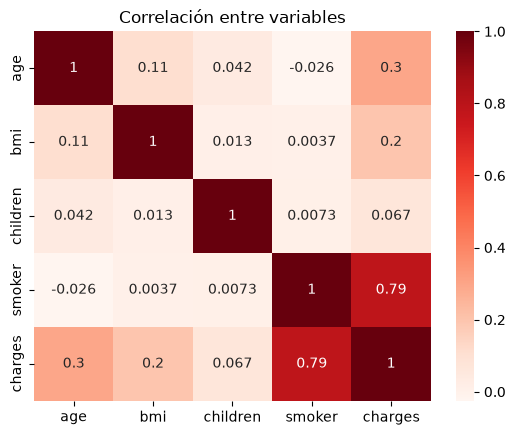

In [7]:
#Copia con fumador como 0/1 para poder incluirlo en la correlación
df_corr = df.copy()
df_corr['smoker'] = (df_corr['smoker'] == 'yes').astype(int)

#Matriz de correlación con los valores en cada casilla
matriz_corr = df_corr.corr().to_pandas()
sns.heatmap(matriz_corr, annot=True, cmap='Reds')
plt.title('Correlación entre variables')
plt.show()

La relación más fuerte, con diferencia, es la de **fumador** con los cargos (0,79): los fumadores pagan mucho más. Le siguen la **edad** (0,30), ya que a más edad más cargos, y el **BMI** (0,20). El número de hijos apenas influye (0,07).

## 3. Análisis univariante

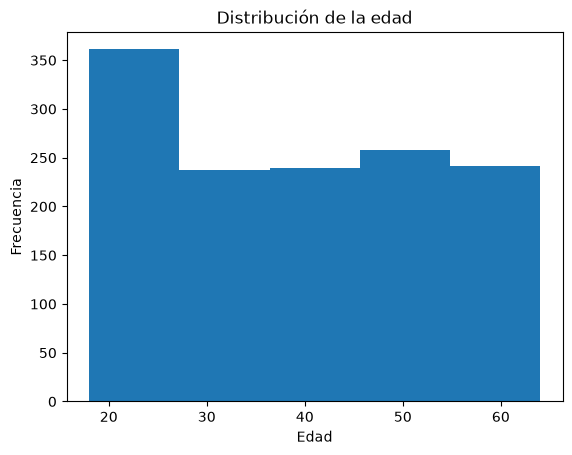

In [8]:
#Distribución de la edad
edad = df['age']

plt.hist(edad, bins=5)
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Distribución de la edad')
plt.show()

La edad está bastante repartida entre los 18 y los 64 años. Solo destaca el primer tramo, el de los más jóvenes, con más clientes que el resto. La media (39) queda más o menos en la mitad.

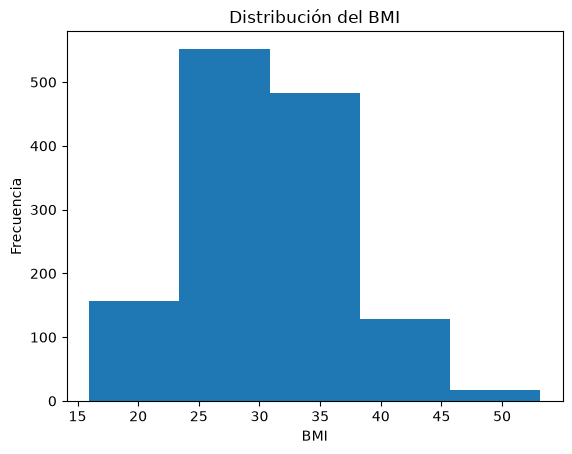

In [9]:
#Distribución del BMI
bmi = df['bmi']

plt.hist(bmi, bins=5)
plt.xlabel('BMI')
plt.ylabel('Frecuencia')
plt.title('Distribución del BMI')
plt.show()

A diferencia de la edad, el BMI no está repartido: la mayoría de los clientes se concentra en los tramos centrales (entre 23 y 38, aproximadamente) y hay pocos en los extremos. Además, en el `describe()` vimos que el 25 % ya está en 26,3, así que al menos 3 de cada 4 clientes superan el BMI ideal (24,9).

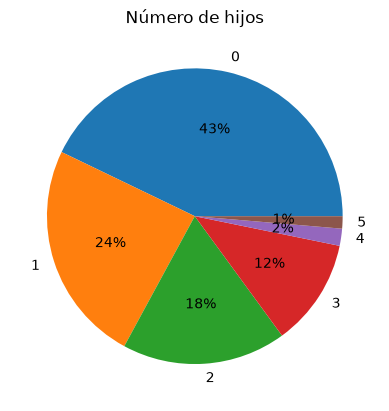

In [10]:
#Reparto de clientes por número de hijos
hijos = df['children'].value_counts().to_pandas()

hijos.plot(kind='pie', autopct='%1.0f%%')
plt.ylabel('')
plt.title('Número de hijos')
plt.show()

El 43 % no tiene hijos y el 24 % tiene uno, así que dos de cada tres clientes tienen 0 o 1 hijo. Con 4 o 5 hijos hay muy pocos.

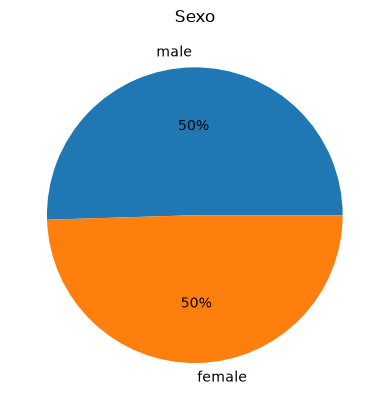

In [11]:
#Reparto de clientes por sexo
sexo = df['sex'].value_counts().to_pandas()

sexo.plot(kind='pie', autopct='%1.0f%%')
plt.ylabel('')
plt.title('Sexo')
plt.show()

Hay los mismos hombres que mujeres (50 % cada uno).

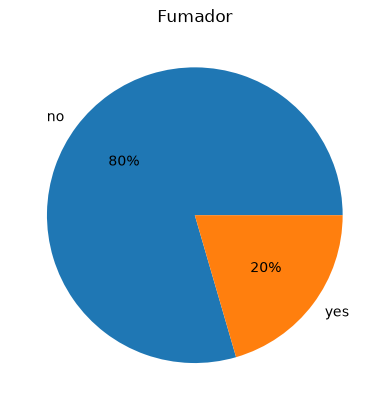

In [12]:
#Reparto de fumadores y no fumadores
fumador = df['smoker'].value_counts().to_pandas()

fumador.plot(kind='pie', autopct='%1.0f%%')
plt.ylabel('')
plt.title('Fumador')
plt.show()

El 80 % no fuma y el 20 % sí, es decir, 1 de cada 5 clientes.

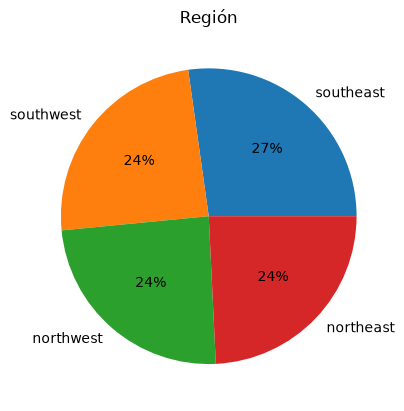

In [13]:
#Reparto de clientes por región
region = df['region'].value_counts().to_pandas()

region.plot(kind='pie', autopct='%1.0f%%')
plt.ylabel('')
plt.title('Región')
plt.show()

Los clientes están repartidos casi a partes iguales entre las cuatro regiones (24-27 %).

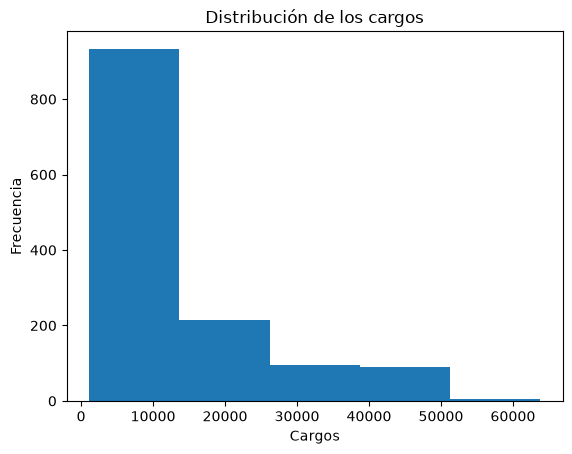

In [14]:
#Distribución de los cargos
charges = df['charges']

plt.hist(charges, bins=5)
plt.xlabel('Cargos')
plt.ylabel('Frecuencia')
plt.title('Distribución de los cargos')
plt.show()

La gran mayoría de los clientes está en el primer tramo, por debajo de unos 13.600, y a partir de ahí hay cada vez menos, aunque algunos superan los 50.000. Por eso la media (13.279) queda por encima de la mediana (9.386) que vimos en el `describe()`: unos pocos clientes con cargos muy altos tiran de la media hacia arriba.

## 4. Análisis bivariante

Vamos a proceder a ver si existe relación entre variables.

In [15]:
#Cargo medio según el sexo
df.groupby('sex')['charges'].mean().round(0)

sex
male      13975.0
female    12570.0
Name: charges, dtype: float64

Los hombres pagan algo más que las mujeres (13.975 frente a 12.570), pero la diferencia es pequeña comparada con la de los fumadores.

In [16]:
#Cargo medio de fumadores y no fumadores
df.groupby('smoker')['charges'].mean().round(0)

smoker
no      8441.0
yes    32050.0
Name: charges, dtype: float64

Los fumadores pagan casi 4 veces más (32.050 frente a 8.441). Es, con diferencia, la variable que más influye.

In [17]:
#Cargo medio según la región
df.groupby('region')['charges'].mean().round(0)

region
northwest    12451.0
southeast    14735.0
northeast    13406.0
southwest    12347.0
Name: charges, dtype: float64

El sureste (southeast) es algo más caro (14.735), y el resto está entre 12.347 y 13.406. La región influye poco.

In [18]:
#Cargo medio según el número de hijos
df.groupby('children')['charges'].mean().sort_index().round(0)

children
0    12385.0
1    12731.0
2    15074.0
3    15355.0
4    13851.0
5     8786.0
Name: charges, dtype: float64

No hay un patrón claro: el cargo sube hasta los 3 hijos y baja con 4 y 5. En la tarta vimos que con 4 o 5 hijos hay muy pocos clientes, así que esas medias son poco fiables.

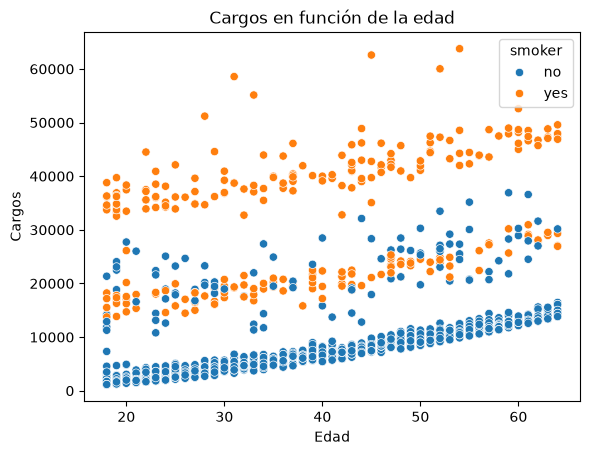

In [19]:
#Cargos según la edad, separando fumadores y no fumadores
pdf = df[['age', 'charges', 'smoker']].to_pandas()

sns.scatterplot(data=pdf, x='age', y='charges', hue='smoker')
plt.xlabel('Edad')
plt.ylabel('Cargos')
plt.title('Cargos en función de la edad')
plt.show()

Los cargos suben con la edad en todos los clientes: se ven franjas que crecen en paralelo. Los fumadores están siempre en las franjas de arriba, así que, a igual edad, pagan mucho más.

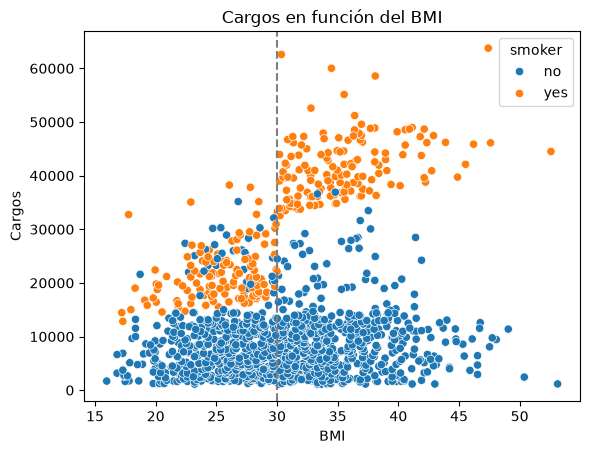

In [20]:
#Cargos según el BMI, separando fumadores y no fumadores
pdf = df[['bmi', 'charges', 'smoker']].to_pandas()

sns.scatterplot(data=pdf, x='bmi', y='charges', hue='smoker')

#Línea en BMI 30: a partir de aquí se considera obesidad
plt.axvline(30, color='gray', linestyle='--')

plt.xlabel('BMI')
plt.ylabel('Cargos')
plt.title('Cargos en función del BMI')
plt.show()

En los no fumadores el BMI apenas cambia los cargos: la mayoría está por debajo de 15.000 tenga el BMI que tenga. En los fumadores, en cambio, hay un salto claro: con BMI por debajo de 30 suelen estar entre 15.000 y 30.000, y por encima de 30 pasan a 35.000-50.000. Lo que encarece el seguro no es el BMI por sí solo, sino **ser fumador con BMI alto**.

Por tanto, lo que más influye en los cargos es ser **fumador**, seguido de la **edad** y del **BMI**, este último sobre todo en los fumadores. Vamos a profundizar en estas variables.

In [21]:
#BMI medio según el sexo
df.groupby('sex')['bmi'].mean().round(1)

sex
male      30.9
female    30.4
Name: bmi, dtype: float64

In [22]:
#BMI medio de fumadores y no fumadores
df.groupby('smoker')['bmi'].mean().round(1)

smoker
no     30.7
yes    30.7
Name: bmi, dtype: float64

In [23]:
#BMI medio según la región
df.groupby('region')['bmi'].mean().round(1)

region
northwest    29.2
southeast    33.4
northeast    29.2
southwest    30.6
Name: bmi, dtype: float64

In [24]:
#BMI medio según el número de hijos
df.groupby('children')['bmi'].mean().sort_index().round(1)

children
0    30.6
1    30.6
2    31.0
3    30.7
4    31.4
5    29.6
Name: bmi, dtype: float64

El BMI medio es casi igual en todos los grupos (entre 29 y 31), salvo en el sureste, donde sube a 33,4, que es también la región con el cargo medio más alto. Fumadores y no fumadores tienen el mismo BMI medio (30,7), así que el salto de los fumadores con BMI alto no se debe a que los fumadores pesen más.

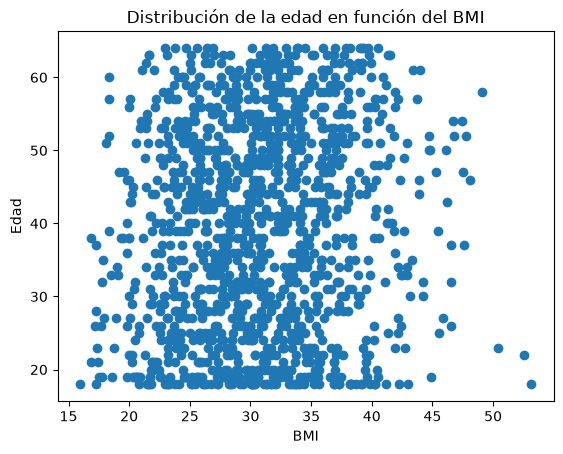

In [25]:
#Relación entre el BMI y la edad
pdf = df[['bmi', 'age']].to_pandas()

plt.scatter(pdf['bmi'], pdf['age'])
plt.xlabel('BMI')
plt.ylabel('Edad')
plt.title('Distribución de la edad en función del BMI')
plt.show()

No hay relación entre el BMI y la edad: los puntos están repartidos por todo el gráfico. Vamos con la siguiente variable (fumador).

In [26]:
#Porcentaje de fumadores según el sexo
#En df_corr, smoker vale 0/1, así que su media es la proporción de fumadores
(df_corr.groupby('sex')['smoker'].mean() * 100).round(1)

sex
male      23.6
female    17.4
Name: smoker, dtype: float64

In [27]:
#Porcentaje de fumadores según el número de hijos
(df_corr.groupby('children')['smoker'].mean() * 100).sort_index().round(1)

children
0    20.1
1    18.8
2    22.9
3    24.8
4    12.0
5     5.6
Name: smoker, dtype: float64

In [28]:
#Porcentaje de fumadores según la región
(df_corr.groupby('region')['smoker'].mean() * 100).round(1)

region
northwest    17.9
southeast    25.0
northeast    20.7
southwest    17.8
Name: smoker, dtype: float64

Los hombres fuman más que las mujeres (23,6 % frente a 17,4 %), y el sureste es la región con más fumadores (25 %). Esto explica por qué los hombres y el sureste tenían un cargo medio algo más alto: no es por el sexo ni por la región en sí, sino porque hay más fumadores (y, en el sureste, también más BMI). Por número de hijos no hay un patrón claro; con 4 y 5 hijos sale más bajo, pero ya vimos que son muy pocos clientes.

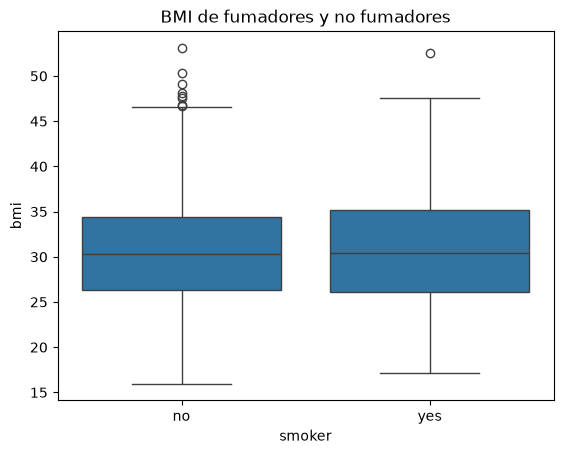

In [29]:
#BMI de fumadores y no fumadores
pdf = df[['smoker', 'bmi']].to_pandas()

sns.boxplot(x=pdf['smoker'], y=pdf['bmi'])
plt.title('BMI de fumadores y no fumadores')
plt.show()

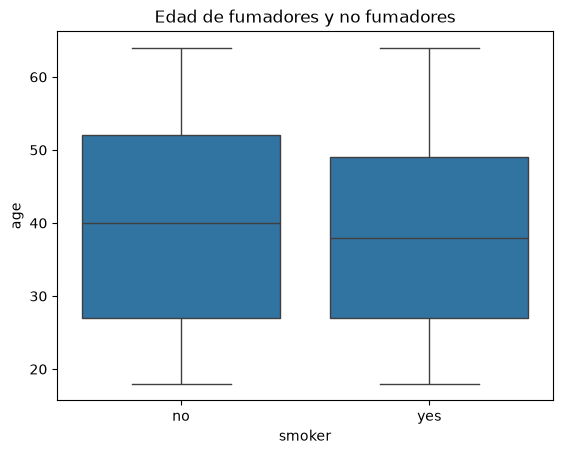

In [30]:
#Edad de fumadores y no fumadores
pdf = df[['smoker', 'age']].to_pandas()

sns.boxplot(x=pdf['smoker'], y=pdf['age'])
plt.title('Edad de fumadores y no fumadores')
plt.show()

Fumadores y no fumadores tienen un BMI y una edad muy parecidos: las cajas casi coinciden. Por tanto, lo que pagan de más los fumadores se debe al tabaco y no a que sean mayores o tengan más BMI.

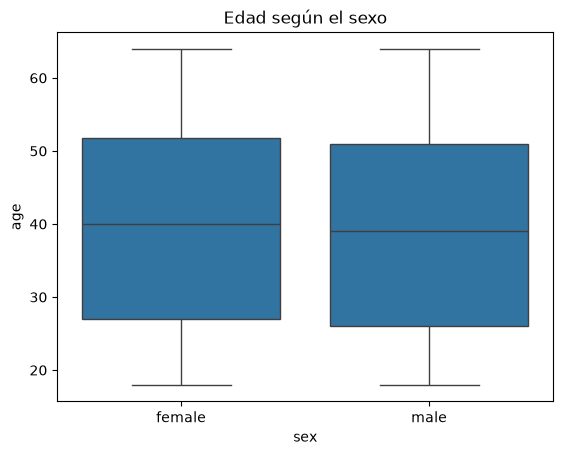

In [31]:
#Edad según el sexo
pdf = df[['sex', 'age']].to_pandas()

sns.boxplot(x=pdf['sex'], y=pdf['age'])
plt.title('Edad según el sexo')
plt.show()

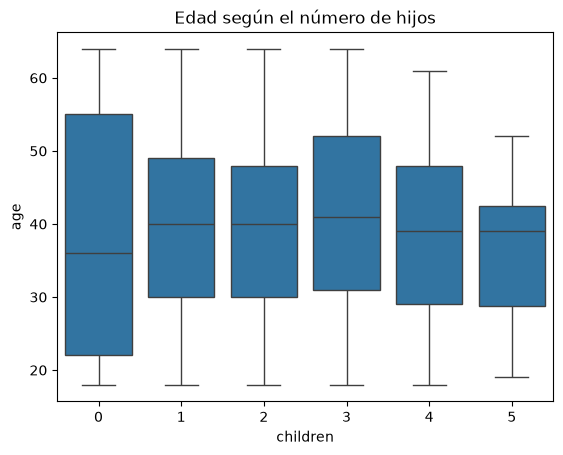

In [32]:
#Edad según el número de hijos
pdf = df[['children', 'age']].to_pandas()

sns.boxplot(x=pdf['children'], y=pdf['age'])
plt.title('Edad según el número de hijos')
plt.show()

La edad es parecida en hombres y mujeres y según el número de hijos. Solo los clientes sin hijos tienden a ser más jóvenes (su caja empieza más abajo), lo cual tiene sentido.

Por tanto, para el modelo de regresión usaremos **fumador**, **edad** y **BMI**. El sexo, la región y el número de hijos apenas influyen por sí mismos: sus diferencias se explicaban por los fumadores.

## 5. Regresión lineal

**Enunciado:** Luego conviertelós a un DataFrame de Spark normal, realiza las conversiones necesarias para poder hacer machine learning (StringIndexer, StandardScaler, VectorAssembler...) y aplica un modelo de regresión lineal usando pyspark.ml

In [33]:
#Pasamos a un DataFrame de Spark normal
spark_df = df.to_spark()
spark_df.printSchema()

root
 |-- age: integer (nullable = true)
 |-- sex: string (nullable = true)
 |-- bmi: double (nullable = true)
 |-- children: integer (nullable = true)
 |-- smoker: string (nullable = true)
 |-- region: string (nullable = true)
 |-- charges: double (nullable = true)



Las tres variables que usaremos para predecir son la edad, el BMI y fumador. Las dos primeras ya son numéricas; fumador es texto, así que la pasamos a número con StringIndexer.

In [34]:
#Fumador como número: StringIndexer da 0 a la opción más frecuente (no) y 1 a la otra (sí)
label_indexer = StringIndexer(inputCol="smoker", outputCol="smoker_label")
label_model = label_indexer.fit(spark_df)
spark_df = label_model.transform(spark_df)

In [35]:
spark_df.show(5)

+---+------+------+--------+------+---------+----------+------------+
|age|   sex|   bmi|children|smoker|   region|   charges|smoker_label|
+---+------+------+--------+------+---------+----------+------------+
| 18|female| 20.79|       0|    no|southeast| 1607.5101|         0.0|
| 18|female| 21.66|       0|   yes|northeast|14283.4594|         1.0|
| 18|female| 24.09|       1|    no|southeast| 2201.0971|         0.0|
| 18|female| 25.08|       0|    no|northeast| 2196.4732|         0.0|
| 18|female|26.315|       0|    no|northeast|2198.18985|         0.0|
+---+------+------+--------+------+---------+----------+------------+
only showing top 5 rows


Después aplicamos OneHotEncoder. Con una variable de solo dos opciones (sí/no) no haría falta, pero lo usamos a modo de práctica.

In [36]:
#Fumador codificado con OneHotEncoder
encoder = OneHotEncoder(inputCol="smoker_label", outputCol="smoker_vec")
encoder_model = encoder.fit(spark_df)
spark_df = encoder_model.transform(spark_df)

In [37]:
spark_df.show(5)

+---+------+------+--------+------+---------+----------+------------+-------------+
|age|   sex|   bmi|children|smoker|   region|   charges|smoker_label|   smoker_vec|
+---+------+------+--------+------+---------+----------+------------+-------------+
| 18|female| 20.79|       0|    no|southeast| 1607.5101|         0.0|(1,[0],[1.0])|
| 18|female| 21.66|       0|   yes|northeast|14283.4594|         1.0|    (1,[],[])|
| 18|female| 24.09|       1|    no|southeast| 2201.0971|         0.0|(1,[0],[1.0])|
| 18|female| 25.08|       0|    no|northeast| 2196.4732|         0.0|(1,[0],[1.0])|
| 18|female|26.315|       0|    no|northeast|2198.18985|         0.0|(1,[0],[1.0])|
+---+------+------+--------+------+---------+----------+------------+-------------+
only showing top 5 rows


Con VectorAssembler juntamos en una sola columna (`features`) las variables que usaremos para predecir.

In [38]:
#Columna features con edad, BMI y fumador
assembler = VectorAssembler(inputCols=["age", "bmi", "smoker_vec"], outputCol="features")
spark_df = assembler.transform(spark_df)

In [39]:
spark_df.show(5)

+---+------+------+--------+------+---------+----------+------------+-------------+-----------------+
|age|   sex|   bmi|children|smoker|   region|   charges|smoker_label|   smoker_vec|         features|
+---+------+------+--------+------+---------+----------+------------+-------------+-----------------+
| 18|female| 20.79|       0|    no|southeast| 1607.5101|         0.0|(1,[0],[1.0])| [18.0,20.79,1.0]|
| 18|female| 21.66|       0|   yes|northeast|14283.4594|         1.0|    (1,[],[])| [18.0,21.66,0.0]|
| 18|female| 24.09|       1|    no|southeast| 2201.0971|         0.0|(1,[0],[1.0])| [18.0,24.09,1.0]|
| 18|female| 25.08|       0|    no|northeast| 2196.4732|         0.0|(1,[0],[1.0])| [18.0,25.08,1.0]|
| 18|female|26.315|       0|    no|northeast|2198.18985|         0.0|(1,[0],[1.0])|[18.0,26.315,1.0]|
+---+------+------+--------+------+---------+----------+------------+-------------+-----------------+
only showing top 5 rows


### Escalado

La edad, el BMI y fumador tienen escalas muy distintas (de 18 a 64, de 16 a 53 y 0/1). Con StandardScaler las dejamos todas con media 0 y desviación 1, para que pesen igual al entrenar la regresión.

In [40]:
#Escalado de la columna features
scaler = StandardScaler(inputCol="features", outputCol="features_scaled")
lr = LinearRegression(featuresCol="features_scaled", labelCol="charges")

#El escalado y la regresión van juntos para que el escalado se ajuste solo con los datos de entrenamiento
pipeline_lr = Pipeline(stages=[scaler, lr])

### Entrenamiento

Dividimos los datos una sola vez en entrenamiento (80 %) y prueba (20 %). El Random Forest usará estos mismos conjuntos, para que la comparación entre los dos modelos sea justa.

In [41]:
train_data, test_data = spark_df.randomSplit([0.8, 0.2], seed=13)

In [42]:
#Combinaciones de hiperparámetros que probará la validación cruzada
paramGrid = (ParamGridBuilder()
             .addGrid(lr.regParam, [0.01, 0.5, 2.0])
             .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0])
             .addGrid(lr.maxIter, [1, 5, 10])
             .build())

In [43]:
#Métrica: MAE (error absoluto medio)
evaluator = RegressionEvaluator(labelCol="charges", predictionCol="prediction", metricName="mae")

In [44]:
#Validación cruzada con 5 folds
crossval = CrossValidator(estimator=pipeline_lr,
                          estimatorParamMaps=paramGrid,
                          evaluator=evaluator,
                          numFolds=5,
                          seed=13)

cvmodel_lr = crossval.fit(train_data)

In [45]:
#Mejores hiperparámetros encontrados por la validación cruzada
mejor_lr = cvmodel_lr.bestModel.stages[-1]
print("regParam:", mejor_lr.getRegParam())
print("elasticNetParam:", mejor_lr.getElasticNetParam())
print("maxIter:", mejor_lr.getMaxIter())

regParam: 2.0
elasticNetParam: 1.0
maxIter: 10


In [46]:
#Coeficientes del mejor modelo (edad, BMI, fumador)
print(mejor_lr.coefficients)

[3676.967849094315,1988.2777886571935,-9701.728519842118]


La validación cruzada eligió `regParam` = 2.0, `elasticNetParam` = 1.0 (regularización Lasso) y `maxIter` = 10.

Como las variables están escaladas, los coeficientes se pueden comparar entre sí: el de **fumador** es el más grande en valor absoluto (9.702), seguido de la **edad** (3.677) y del **BMI** (1.988), el mismo orden que vimos en el EDA. El de fumador sale negativo porque, tras el OneHotEncoder, esa columna vale 1 para los **no** fumadores (lo vimos en el `show()`): no fumar baja el cargo.

### Evaluación

Evaluamos el mejor modelo con los datos de prueba.

In [47]:
prediction_lr = cvmodel_lr.transform(test_data)

mae_lr = evaluator.evaluate(prediction_lr)
print("MAE:", mae_lr)

MAE: 4287.741948630557


Usamos el MAE porque es el promedio de las diferencias absolutas entre la predicción y el valor real. El modelo falla de media **4.288 dólares**. Comparado con el cargo medio (13.279, en el `describe()`), es un error de alrededor del 32 %. Vamos a probar con un Random Forest.

## 6. Random Forest

Usamos los mismos `train_data` y `test_data` que en la regresión lineal. El Random Forest no necesita escalado (decide cortando cada variable por valores, sin importar su escala), así que entrena directamente con `features`.

In [48]:
#Semilla fija para que el resultado sea siempre el mismo
rf = RandomForestRegressor(featuresCol="features", labelCol="charges", predictionCol="prediction", seed=13)

In [49]:
#Hiperparámetros propios del Random Forest: número de árboles y profundidad máxima
paramGrid_rf = (ParamGridBuilder()
                .addGrid(rf.numTrees, [10, 50, 100])
                .addGrid(rf.maxDepth, [5, 10, 20])
                .build())

In [50]:
#Validación cruzada con 5 folds y la misma métrica (MAE)
crossval_rf = CrossValidator(estimator=rf,
                             estimatorParamMaps=paramGrid_rf,
                             evaluator=evaluator,
                             numFolds=5,
                          seed=13)

cvmodel_rf = crossval_rf.fit(train_data)

In [51]:
#Mejores hiperparámetros encontrados por la validación cruzada
mejor_rf = cvmodel_rf.bestModel
print("numTrees:", mejor_rf.getNumTrees)
print("maxDepth:", mejor_rf.getMaxDepth())

numTrees: 10
maxDepth: 20


In [52]:
prediction_rf = cvmodel_rf.transform(test_data)

mae_rf = evaluator.evaluate(prediction_rf)
print("MAE:", mae_rf)

MAE: 3208.5593670901408


### Comparación

In [53]:
#MAE de los dos modelos con los mismos datos de prueba
print("MAE Regresión lineal:", round(mae_lr))
print("MAE Random Forest:   ", round(mae_rf))
print("Diferencia:          ", round(mae_lr - mae_rf))

MAE Regresión lineal: 4288
MAE Random Forest:    3209
Diferencia:           1079


Con los mismos datos de prueba, el **Random Forest** se equivoca de media 3.209 dólares, frente a los 4.288 de la regresión lineal: 1.079 menos, un 25 % menos de error. Por eso elegimos el Random Forest (con 10 árboles y profundidad máxima 20, los mejores según la validación cruzada).

Una razón probable es que los árboles captan por sí solos el salto que vimos en los fumadores con BMI por encima de 30, algo que una regresión lineal con estas tres variables no puede representar.

## 7. Conclusiones

**Hallazgos**

- Lo que más encarece el seguro es **ser fumador**: los fumadores pagan casi 4 veces más (32.050 frente a 8.441), es la variable con más correlación con los cargos (0,79) y la de mayor coeficiente en la regresión.
- La **edad** sube los cargos en todos los clientes.
- El **BMI** solo encarece de verdad en los fumadores: un fumador con BMI por encima de 30 pasa a pagar entre 35.000 y 50.000.
- El sexo, la región y el número de hijos apenas influyen: sus pequeñas diferencias se explican por la proporción de fumadores de cada grupo.
- El **Random Forest** es el mejor modelo: falla de media 3.209 dólares, frente a los 4.288 de la regresión lineal.

**Limitaciones**

- Son pocos datos (1.337 clientes) y pocas variables, y el error sigue siendo alto: alrededor del 24 % del cargo medio en el mejor modelo.
- Los modelos se evalúan con un único conjunto de prueba (el 20 % de los datos), así que el MAE podría variar algo con otro reparto.
- Algunos de los mejores hiperparámetros salieron en el extremo de la rejilla (`regParam` = 2.0 y `maxDepth` = 20), así que podría haber valores mejores fuera de ella.

**Próximos pasos**

- Añadir a la regresión lineal una variable que combine fumador y BMI por encima de 30, la relación que vimos en el EDA.
- Ampliar la rejilla de hiperparámetros por los extremos.
- Probar otros modelos de `pyspark.ml`, como `GBTRegressor`.